# Part 2: Single-Stock Risk Report

This notebook makes a risk report for **one stock**. It reads the cleaned table `ohlc_hw_cleaned` from Part 1. Papermill can run it again with other parameters, so Part 3 can make a report for every ticker.

The report uses the **adjusted close** and **daily log returns**, as the homework says.

## 2.1 Parameters

The next cell holds the settings. Papermill replaces these values when it runs the notebook for another stock.

The cell has the metadata tag **`parameters`**. A comment alone is not enough. `db_path` is the path to my working copy of the database. Part 3 gives papermill a full path, so the report also works when it is saved in another folder.


In [1]:
# Parameters
ticker = "AAPL"            # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"    # Analysis end date
db_path = "data/data.db"   # Path to the working copy of the database

### Imports and colors

In [2]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.lines import Line2D

plt.style.use("seaborn-v0_8-whitegrid")
GREEN, RED, NAVY, GRAY = "#2e7d32", "#c62828", "#1a237e", "#9e9e9e"

## 2.2 Data Loading

I load the cleaned rows for one ticker and one date range. The database is opened **read-only**, so the report cannot change it.

The cell stops with a clear message in these cases:
- the database file is missing
- the start date is after the end date
- the ticker has no rows in the range
- there are fewer than 21 prices (20 returns need 21 prices)
- the cleaned prices contain a missing, non-finite, or non-positive value

Then it prints the number of trading days, and the **actual** first and last dates in the data. The actual dates can differ from the dates I asked for, because some tickers end earlier than others.

In [3]:
database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f"Database not found: {database}")
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError("start_date must be on or before end_date.")

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date),
                           parse_dates=["ts"], index_col="ts")

if df.empty:
    raise ValueError(f"{ticker}: no cleaned rows between {start_date} and {end_date}.")
if len(df) < 21:
    raise ValueError(f"{ticker}: only {len(df)} prices. 20 returns need at least 21 prices.")

prices_ok = np.isfinite(df[["open", "high", "low", "close", "adj_close"]]).all().all() \
    and (df[["open", "high", "low", "close", "adj_close"]] > 0).all().all()
if not prices_ok:
    raise ValueError(f"{ticker}: cleaned table has missing, non-finite or non-positive prices.")
assert df.index.is_monotonic_increasing and df.index.is_unique

first_obs, last_obs = df.index[0].date(), df.index[-1].date()
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual first observation: {first_obs}   Actual last observation: {last_obs}")
display(df.head())
display(df.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual first observation: 2024-01-02   Actual last observation: 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


**Reading the output:** The first line gives the number of trading days. The second line gives the real coverage. In the default run (AAPL, 2024), the data starts on 2024-01-02 but ends on **2024-10-18**, not on 2024-12-31. The supplied history of AAPL ends on that date. The report does not invent prices after it.

## 2.3 Risk Metrics

Four functions, one for each measure.

| Function | What it returns |
|---|---|
| `calculate_returns` | Daily **log** returns: `log(price today / price yesterday)`. The first value is missing. |
| `calculate_volatility` | Rolling 20-day standard deviation of the returns, times `sqrt(252)` to annualize. It stays missing until 20 returns exist. I do not fill the warm-up with zero. |
| `calculate_max_drawdown` | **Per-date drawdown** from the running price peak. The name is the one the homework asks for. The Series can recover toward 0. The maximum drawdown is its minimum. |
| `calculate_sharpe_ratio` | `(mean × 252 − 2%) / (std × sqrt(252))`. It returns `NaN` if there are fewer than 2 returns or the volatility is zero. |

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns: log(price today / price yesterday). The first value is NaN."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling volatility: rolling sample std of returns times sqrt(252).

    Values stay NaN until a full window of returns exists.
    """
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running price peak (0 at a new high, negative below it).

    The maximum drawdown for the summary is the minimum of this Series.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Annualized Sharpe ratio: (mean * 252 - rf) / (std * sqrt(252)).

    Returns NaN when there are fewer than 2 returns or the volatility is zero.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * 252 - risk_free_rate) / (sigma * np.sqrt(252))

### Check the functions by hand

For prices 100, 110, 99:
- the second log return is `log(1.1)`
- the drawdowns are 0, 0, and −10% (the peak is 110 and the price falls to 99)
- two equal returns have zero volatility, so the Sharpe ratio is undefined (`NaN`)

In [5]:
test_prices = pd.Series([100.0, 110.0, 99.0])
assert np.isclose(calculate_returns(test_prices).iloc[1], np.log(1.1))
assert np.allclose(calculate_max_drawdown(test_prices), [0, 0, -0.10])
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))
print("function tests passed")

function tests passed


### Apply the functions

All measures use the **adjusted close**. The 50-day average needs 50 prices. It stays missing before that.

In [6]:
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"])
df["sma_50"] = df["adj_close"].rolling(50).mean()
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["cumulative_return"] = df["adj_close"] / df["adj_close"].iloc[0] - 1

display(df[["adj_close", "log_return", "volatility", "sma_50", "drawdown"]].tail())

,adj_close,log_return,volatility,sma_50,drawdown
ts,,,,,
2024-10-14,231.30,0.016346,0.242503,223.6422,-0.013856
2024-10-15,233.85,0.010964,0.243942,224.1386,-0.002984
2024-10-16,231.78,-0.008891,0.241973,224.6344,-0.011810
2024-10-17,232.15,0.001595,0.206097,225.0858,-0.010232
2024-10-18,235.00,0.012202,0.209521,225.5246,0.000000


## 2.4 Visualization

A 2x2 figure, 16 by 12 inches.

| Panel | Content |
|---|---|
| Top left | Adjusted close. The line is **red** where the rolling volatility is above its mean for the report, **green** where it is at or below the mean, and **gray** while the volatility is not yet available. A dashed navy line is the 50-day average. |
| Top right | Daily log returns as bars: green for positive, red for negative. A black line marks zero. |
| Bottom left | Rolling 20-day volatility with a line at its mean. The area above the mean is shaded red and the area below is shaded green. |
| Bottom right | Drawdown as a red area. Five transparent layers make a gradient. A black dot marks the maximum drawdown. |

The colors use the **mean for the whole report**, so they look back on the data. If a report has fewer than 50 prices, the figure says that the 50-day average is not available.

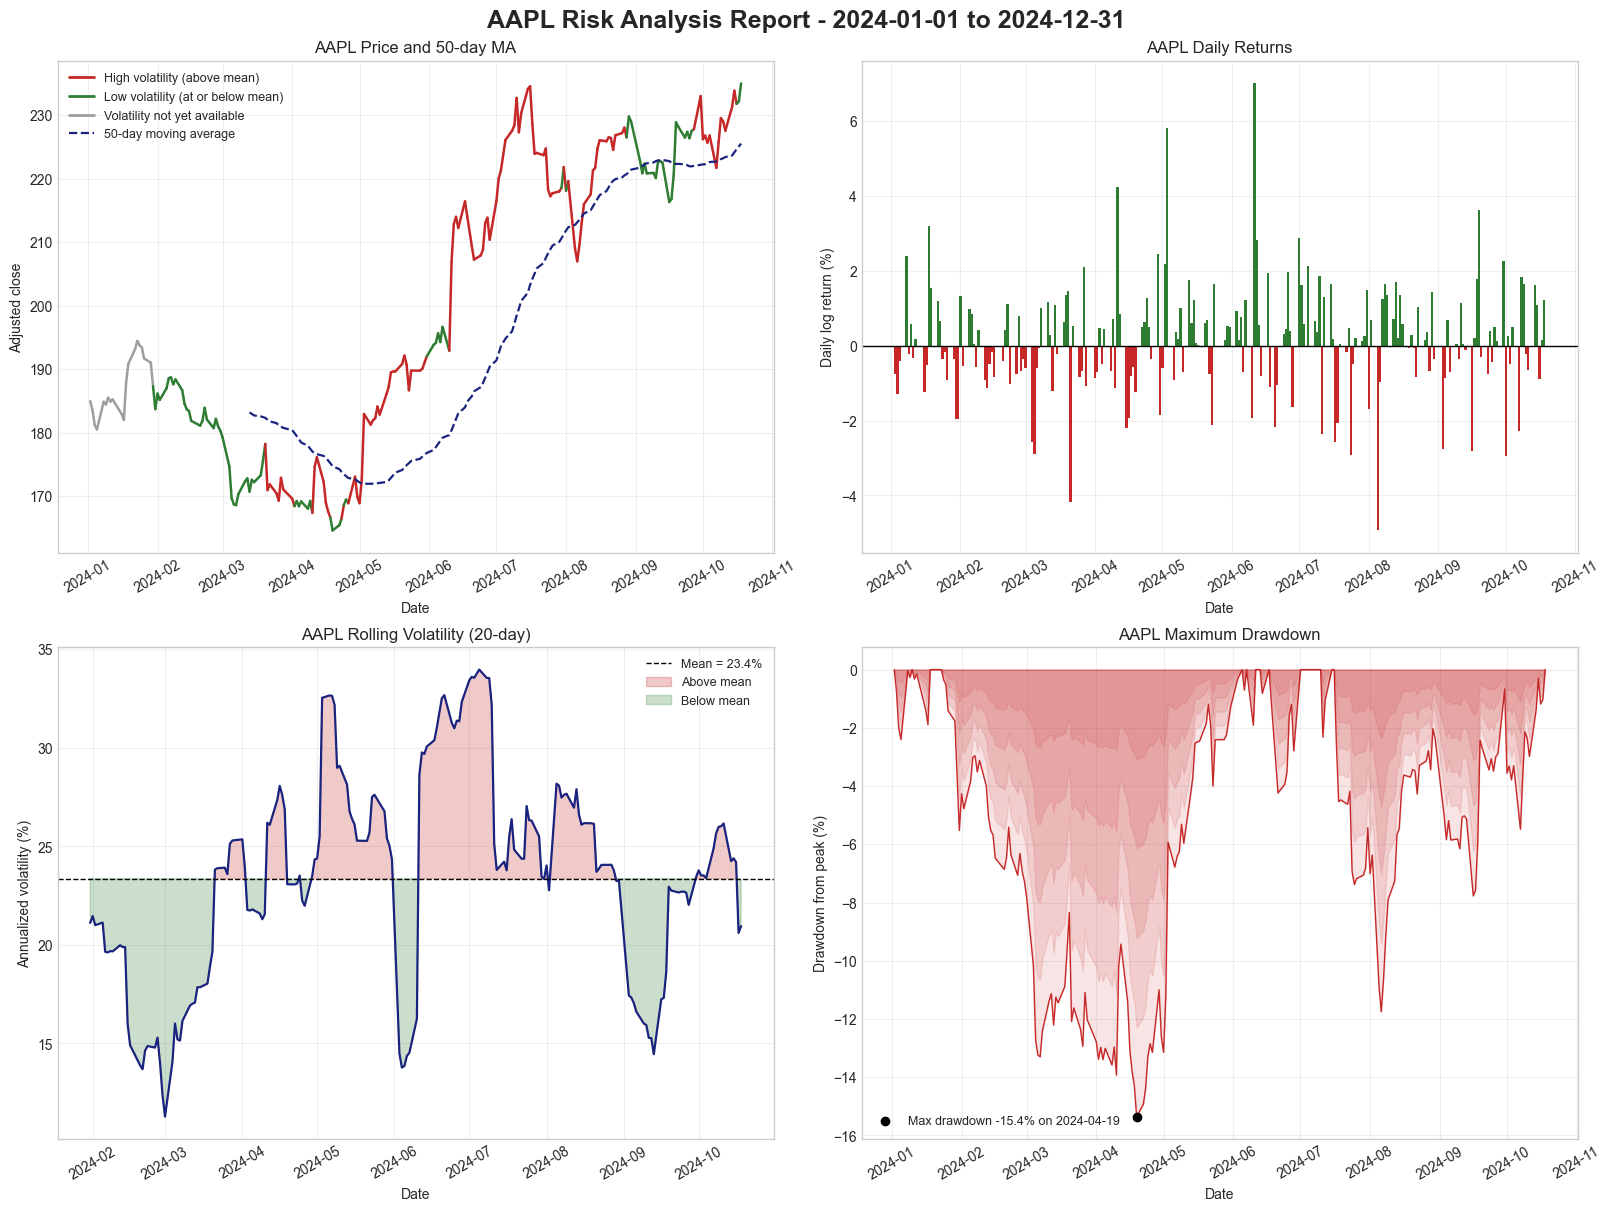

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
             fontsize=18, fontweight="bold")
mean_vol = df["volatility"].mean()

# Top left: price, colored by volatility, with the 50-day average
ax = axes[0, 0]
for i in range(1, len(df)):
    vol = df["volatility"].iloc[i]
    color = GRAY if pd.isna(vol) else (RED if vol > mean_vol else GREEN)
    ax.plot(df.index[i - 1:i + 1], df["adj_close"].iloc[i - 1:i + 1], color=color, linewidth=1.8)
ax.plot(df.index, df["sma_50"], color=NAVY, linestyle="--", linewidth=1.6)
handles = [Line2D([0], [0], color=RED, lw=2, label="High volatility (above mean)"),
           Line2D([0], [0], color=GREEN, lw=2, label="Low volatility (at or below mean)"),
           Line2D([0], [0], color=GRAY, lw=2, label="Volatility not yet available"),
           Line2D([0], [0], color=NAVY, lw=1.6, ls="--", label="50-day moving average")]
ax.legend(handles=handles, loc="best", fontsize=9)
if df["sma_50"].isna().all():
    ax.text(0.5, 0.04, f"50-day average unavailable: only {len(df)} prices (needs 50)",
            transform=ax.transAxes, ha="center", fontsize=10, color=NAVY)
ax.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close")

# Top right: daily log returns
ax = axes[0, 1]
ax.bar(df.index, df["log_return"] * 100, width=1.0,
       color=np.where(df["log_return"] >= 0, GREEN, RED))
ax.axhline(0, color="black", linewidth=1)
ax.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return (%)")

# Bottom left: rolling volatility
ax = axes[1, 0]
vol_pct = df["volatility"] * 100
ax.plot(df.index, vol_pct, color=NAVY, linewidth=1.6)
ax.axhline(mean_vol * 100, color="black", linestyle="--", linewidth=1,
           label=f"Mean = {mean_vol * 100:.1f}%")
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=(vol_pct > mean_vol * 100),
                color=RED, alpha=0.25, interpolate=True, label="Above mean")
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=(vol_pct < mean_vol * 100),
                color=GREEN, alpha=0.25, interpolate=True, label="Below mean")
ax.legend(loc="best", fontsize=9)
ax.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date",
       ylabel="Annualized volatility (%)")

# Bottom right: drawdown (layered transparent fills make a gradient)
ax = axes[1, 1]
dd_pct = df["drawdown"] * 100
for k in range(1, 6):
    ax.fill_between(df.index, dd_pct * k / 5, 0, color=RED, alpha=0.12)
ax.plot(df.index, dd_pct, color=RED, linewidth=1)
trough_date = df["drawdown"].idxmin()
trough_value = df["drawdown"].min() * 100
ax.scatter([trough_date], [trough_value], color="black", zorder=5,
           label=f"Max drawdown {trough_value:.1f}% on {trough_date.date()}")
ax.legend(loc="lower left", fontsize=9)
ax.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from peak (%)")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

plt.show()

## 2.5 Summary Statistics

Definitions:
- **Total return** = last adjusted close / first adjusted close − 1.
- **Annualized return** = `exp(sum of log returns × 252 / n) − 1`, where `n` is the number of non-missing log returns.
- **Annualized volatility** = standard deviation of all log returns × `sqrt(252)`. This is the **whole period** number. It is not the same as the mean of the rolling volatility.
- **Maximum drawdown** = the minimum of the drawdown Series.
- **Best day, worst day, up day average, down day average** use log returns.
- **Positive days** = days with a positive return divided by **all** non-missing returns. A zero return day counts in the total.
- If there is no up day or no down day, the average shows N/A.

I keep fractions in the calculations and format them as percentages only for display.

In [8]:
log_returns = df["log_return"].dropna()
n = len(log_returns)

total_return = df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1
annualized_return = np.expm1(log_returns.sum() * 252 / n) if n > 0 else np.nan
annualized_vol = log_returns.std() * np.sqrt(252) if n > 1 else np.nan
sharpe = calculate_sharpe_ratio(log_returns)
max_drawdown = df["drawdown"].min()
best_day = log_returns.max() if n > 0 else np.nan
worst_day = log_returns.min() if n > 0 else np.nan
positive_share = (log_returns > 0).sum() / n if n > 0 else np.nan
avg_up = log_returns[log_returns > 0].mean()      # NaN if there is no up day
avg_down = log_returns[log_returns < 0].mean()    # NaN if there is no down day


def pct(x, signed=True):
    """Format a fraction as a percentage string, or N/A."""
    if x is None or pd.isna(x):
        return "N/A"
    return f"{x * 100:+.2f}%" if signed else f"{x * 100:.2f}%"


rows = [
    ("Total Return", pct(total_return)),
    ("Annualized Return", pct(annualized_return)),
    ("Annualized Volatility", pct(annualized_vol, signed=False)),
    ("Sharpe Ratio", "N/A" if pd.isna(sharpe) else f"{sharpe:.2f}"),
    ("Maximum Drawdown", pct(max_drawdown)),
    ("Best Day", pct(best_day)),
    ("Worst Day", pct(worst_day)),
    ("Positive Days", pct(positive_share, signed=False)),
    ("Average Up Day", pct(avg_up)),
    ("Average Down Day", pct(avg_down)),
]
print(f"{'Metric':<24} {'Value':>10}")
print(f"{'-' * 24} {'-' * 10}")
for name, value in rows:
    print(f"{name:<24} {value:>10}")

Metric                        Value
------------------------ ----------
Total Return                +27.07%
Annualized Return           +35.03%
Annualized Volatility        23.61%
Sharpe Ratio                   1.19
Maximum Drawdown            -15.35%
Best Day                     +7.01%
Worst Day                    -4.94%
Positive Days                55.72%
Average Up Day               +1.08%
Average Down Day             -1.09%


### Save the results for the batch run

`sb.glue` saves named values inside the executed notebook. Part 3 reads them from each successful report. This is safer than reading every file in the folder, because failed and old reports can be there too.

All values are **fractions** (not percentages). An undefined value is saved as `None`.

In [9]:
def as_number(x):
    """Plain float for Scrapbook; None when undefined."""
    return None if x is None or pd.isna(x) else float(x)


sb.glue("ticker", ticker)
sb.glue("start_date", start_date)
sb.glue("end_date", end_date)
sb.glue("first_observation", str(first_obs))
sb.glue("last_observation", str(last_obs))
sb.glue("trading_days", int(len(df)))
sb.glue("avg_daily_return", as_number(log_returns.mean()))
sb.glue("avg_volatility", as_number(df["volatility"].mean()))
sb.glue("max_drawdown", as_number(max_drawdown))
sb.glue("sharpe_ratio", as_number(sharpe))
sb.glue("total_return", as_number(total_return))